# 🏦 Home Loan Approval Predictor — from data to a deployed app

**The business question:** A bank gets thousands of home-loan applications every month.
Can we use past decisions to predict whether a new application should be approved?

**Why it matters — two kinds of mistakes:**
- ❌ Reject a good customer → the bank loses business (and the customer goes to a competitor)
- ❌ Approve a risky customer → the bank may lose lakhs of rupees if the loan is not repaid

**Our journey today:** Data → Clean → Features → Train → Evaluate → Save → Deploy → Use

> Note: real bank data is private, so `data/loans.csv` is a realistic synthetic dataset built on real Indian lending rules (CIBIL score, EMI-to-income ratio, loan-to-value). It is deliberately messy — just like real data.

## Step 1 · Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from loan_utils import clean, add_features, FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET

df = pd.read_csv("data/loans.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (5060, 13)


,applicant_id,age,employment_type,city_tier,dependents,monthly_income,coapplicant_income,credit_score,existing_emis,property_value,loan_amount,loan_term_months,loan_approved
0,APP104087,58,BUSINESS,Tier 1,3+,53900.0,0.0,801.0,17700.0,4260000.0,2730000.0,240,Y
1,APP101542,24,Salaried,Tier 1,2,139000.0,0.0,650.0,33100.0,12140000.0,9410000.0,240,N
2,APP100078,43,Salaried,Tier 1,0,28600.0,22800.0,787.0,2900.0,1730000.0,1420000.0,240,Y
3,APP102554,60,Self-Employed,Tier 3,3+,33600.0,0.0,646.0,5700.0,2220000.0,1640000.0,180,N
4,APP101580,32,Salaried,Tier 2,1,43400.0,0.0,NaN,0.0,4360000.0,2920000.0,240,N


## Step 2 · Look before you leap (explore)
First question: how many applications were approved?

In [2]:
df[TARGET].value_counts(normalize=True).round(3)

loan_approved
Y    0.694
N    0.306
Name: proportion, dtype: float64

Now let's find the problems. **Real data is never clean.**

In [3]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
employment_type       152
dependents            100
coapplicant_income    203
credit_score          303
dtype: int64

Duplicate rows: 60


In [4]:
# Same job written 6 different ways by different branch staff!
df["employment_type"].value_counts(dropna=False)

employment_type
Salaried         2902
Self-Employed    1047
Business          661
salaried          184
NaN               152
self employed      72
BUSINESS           42
Name: count, dtype: int64

In [5]:
df["city_tier"].value_counts(dropna=False)

city_tier
Tier 1    2192
Tier 2    1746
Tier 3     971
T1          77
T2          55
T3          19
Name: count, dtype: int64

In [6]:
# Income typos: someone earning ₹0, someone earning crores per month?
df["monthly_income"].describe().round(0)

count       5060.0
mean       90351.0
std        63890.0
min            0.0
25%        56100.0
50%        78800.0
75%       109900.0
max      1564000.0
Name: monthly_income, dtype: float64

## Step 3 · Clean the data
All cleaning lives in `loan_utils.py`, so the **app uses the exact same rules** later. (A very common industry bug: cleaning data one way in training and another way in production.)

In [7]:
df = df.drop_duplicates()
df = clean(df)
print("Rows after removing duplicates:", len(df))
df["employment_type"].value_counts(dropna=False)

Rows after removing duplicates: 5000


employment_type
Salaried         3052
Self-Employed    1099
Business          699
NaN               150
Name: count, dtype: int64

## Step 4 · Feature engineering — think like a loan officer
A loan officer doesn't just look at income. They look at **ratios**:

| Feature | Meaning | Why it matters |
|---|---|---|
| `new_emi` | Monthly EMI for this loan (at 9%) | What the customer must pay every month |
| `foir` | (All EMIs) ÷ (Total income) | Banks get nervous above ~50–60% |
| `ltv` | Loan ÷ Property value | RBI caps how much of a home's value banks can lend |
| `years_past_60` | Years the loan runs after age 60 | Retirement risk |

In [8]:
df = add_features(df)
df[["monthly_income", "new_emi", "foir", "ltv", "years_past_60"]].head().round(2)

,monthly_income,new_emi,foir,ltv,years_past_60
0,53900.0,24562.52,0.78,0.64,18.0
1,139000.0,84664.21,0.85,0.78,0.0
2,28600.0,12776.11,0.30,0.82,3.0
3,33600.0,16633.97,0.66,0.74,15.0
4,43400.0,26272.00,0.61,0.67,0.0


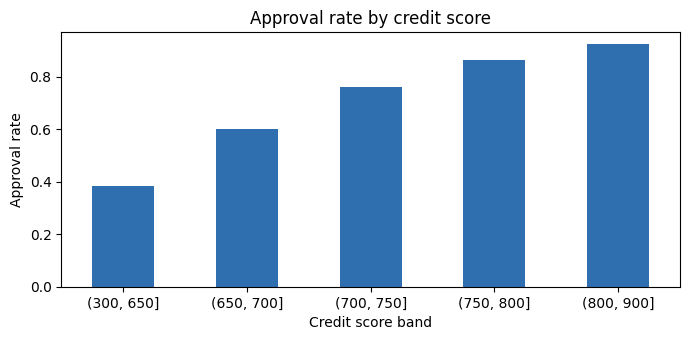

In [9]:
# Does credit score really matter? Approval rate by CIBIL band
bands = pd.cut(df["credit_score"], [300, 650, 700, 750, 800, 900])
rate = (df[TARGET] == "Y").groupby(bands, observed=True).mean()
rate.plot(kind="bar", color="#2f6fb0", figsize=(7, 3.5), rot=0,
          title="Approval rate by credit score")
plt.ylabel("Approval rate"); plt.xlabel("Credit score band"); plt.tight_layout(); plt.show()

## Step 5 · Split: training data vs. test data
We hide 20% of the data. The model never sees it while learning — it's the **final exam**.

In [10]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = (df[TARGET] == "Y").astype(int)        # 1 = approved, 0 = rejected

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4000, 14)  Test: (1000, 14)


## Step 6 · Train model #1 — Logistic Regression (the baseline)
You learned this in theory class. In industry we put it inside a **Pipeline**:
fill missing values → scale numbers → one-hot encode text → model.
One object does everything, so deployment is easy.

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC_FEATURES),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_FEATURES),
])

logreg = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))])
logreg.fit(X_train, y_train)
print("Logistic Regression accuracy:", round(logreg.score(X_test, y_test), 3))

Logistic Regression accuracy: 0.819


## Step 7 · Train model #2 — Random Forest (the challenger)
'Many decision trees voting together.' Usually stronger… let's see.

In [12]:
from sklearn.ensemble import RandomForestClassifier

forest = Pipeline([("prep", preprocess),
                   ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                    random_state=42, n_jobs=-1))])
forest.fit(X_train, y_train)
print("Random Forest accuracy:", round(forest.score(X_test, y_test), 3))

Random Forest accuracy: 0.804


## Step 8 · Evaluate — accuracy is not enough

In [13]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

rows = []
for name, m in [("Logistic Regression", logreg), ("Random Forest", forest)]:
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "accuracy": (pred == y_test).mean(),
        "precision (of approved, % truly good)": precision_score(y_test, pred),
        "recall (of good customers, % approved)": recall_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })
pd.DataFrame(rows).set_index("model").round(3)

,accuracy,"precision (of approved, % truly good)","recall (of good customers, % approved)",ROC-AUC
model,,,,
Logistic Regression,0.819,0.835,0.921,0.867
Random Forest,0.804,0.821,0.916,0.851


💡 **Surprise:** the simple model wins (or ties). In banking this is common — and logistic regression is
**easy to explain** to customers and regulators. Lesson: *always start simple; a complex model must earn its place.*

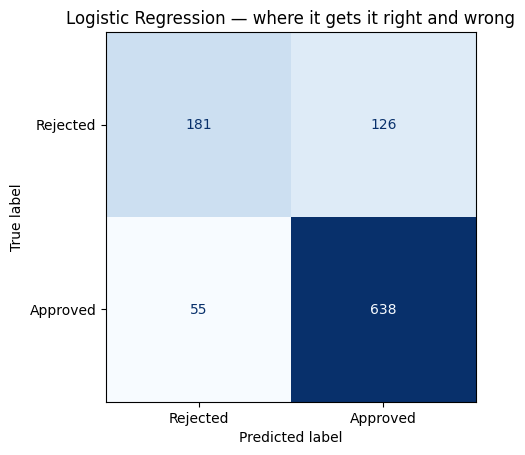

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test,
    display_labels=["Rejected", "Approved"], cmap="Blues", colorbar=False)
plt.title("Logistic Regression — where it gets it right and wrong"); plt.show()

### The bank's real question: how strict should we be?
The model gives a **probability**. The bank chooses the cut-off (threshold).
Stricter cut-off → fewer bad loans, but more good customers turned away. This is a **business** decision, not a maths one.

In [15]:
prob = logreg.predict_proba(X_test)[:, 1]
table = []
for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    approve = prob >= t
    table.append({
        "approve if probability ≥": t,
        "% of applicants approved": approve.mean(),
        "of approved, % truly good (precision)": y_test[approve].mean(),
        "of good customers, % we approved (recall)": approve[y_test == 1].mean(),
    })
pd.DataFrame(table).round(3)

,approve if probability ≥,% of applicants approved,"of approved, % truly good (precision)","of good customers, % we approved (recall)"
0,0.4,0.819,0.802,0.948
1,0.5,0.764,0.835,0.921
2,0.6,0.705,0.855,0.870
3,0.7,0.616,0.888,0.789
4,0.8,0.498,0.920,0.661


## Step 9 · Explain — what drives the decision?

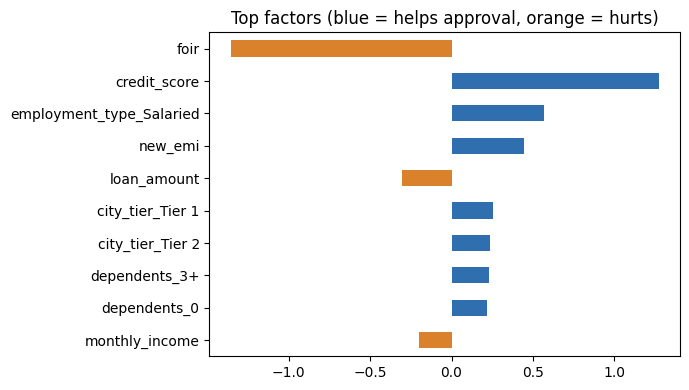

In [16]:
names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=names)
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
top = coefs.reindex(coefs.abs().sort_values().index).tail(10)
top.plot(kind="barh", color=np.where(top > 0, "#2f6fb0", "#d9822b"), figsize=(7, 4),
         title="Top factors (blue = helps approval, orange = hurts)")
plt.tight_layout(); plt.show()

## Step 10 · Save the model — this file is what we deploy

In [17]:
import joblib, os
os.makedirs("model", exist_ok=True)
joblib.dump(logreg, "model/loan_model.joblib")
print("Saved model/loan_model.joblib —", round(os.path.getsize("model/loan_model.joblib") / 1024, 1), "KB")

Saved model/loan_model.joblib — 5.3 KB


In [18]:
# Quick test: a brand-new applicant, exactly like the app will send it
new_applicant = pd.DataFrame([{
    "age": 32, "employment_type": "Salaried", "city_tier": "Tier 1", "dependents": "1",
    "monthly_income": 120000, "coapplicant_income": 0, "credit_score": 760,
    "existing_emis": 8000, "property_value": 8000000, "loan_amount": 6000000,
    "loan_term_months": 240,
}])
model = joblib.load("model/loan_model.joblib")
p = model.predict_proba(add_features(clean(new_applicant))[FEATURES])[0, 1]
print(f"Approval probability: {p:.0%}")

Approval probability: 91%


## Step 11 · Deploy and use → see `app.py`
```
streamlit run app.py
```
Then push the folder to GitHub and deploy free on **Streamlit Community Cloud** or **Hugging Face Spaces**.

### What happens *after* deployment in a real company
- **Monitoring:** track predictions and real outcomes every week
- **Data drift:** interest rates, salaries and property prices change → the model slowly gets worse
- **Retraining:** rebuild the model on fresh data on a schedule
- **Fairness checks:** make sure the model isn't unfair to any group of customers